# Data extraction and descriptive analysis

In [122]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold,
)
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve,
)
from xgboost import XGBClassifier

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

df_dc = pd.read_csv("data/raw/BD_DC.csv", sep="\t")
df_cl = pd.read_csv("data/raw/BD_clientes.csv", sep="\t")


In [66]:
df_dc.head()

,id,tipo_empresa,codpostal,municipio,provincia,comunidadautonoma,capitalpueblo,enpoligono,habitantes_municipio,tipo_de_zona,actcnae,mercado,cnae_mercado,rangoventas,rangoempleados,numoficinas,tipooficina,anyofundacion,nse,tendenciaempleados,tendenciaingresos,flotaturismos,flotafurgonetas,flotacamiones,flotaautobuses,riesgo,universo,existe_import,existe_export,existe_importexport,existe_email,es_ecommerce,impactos_publicidad
0,1,E,46008,VALENCIA,VALENCIA,COMUNITAT VALENCIANA,CAPITAL,0,786189,7,PINTURA Y ACRISTALAMIENTO,CONSTRUCCION Y OBRAS PUBLICAS,CONSTRUCCION,7.0,125.0,NaN,SEDE,31/07/1989,4,POSITIVA LINEAL,POSITIVA NO LINEAL,0,0,0,0,NaN,ACTIVEBUSINESS,0,0,0,1,0,3
1,2,E,28049,MADRID,MADRID,MADRID,CAPITAL,0,3141991,7,OTROS SERVICIOS RELACIONADOS CON LAS TECNOLOGÍ...,TELECOMUNICACIONES,INFORMACION Y COMUNICACIONES,1.0,NaN,NaN,SEDE,22/05/2012,3,NaN,NaN,0,0,0,0,NaN,MARKETBASE,0,0,0,1,0,2
2,3,E,8172,SANT CUGAT DEL VALLÈS,BARCELONA,CATALUNYA,PUEBLO,0,87830,5,PELUQUERÍA Y OTROS TRATAMIENTOS DE BELLEZA,COSMETICA Y CUIDADO PERSONAL,OTROS SERVICIOS,7.0,135.0,NaN,SEDE,01/01/1999,5,POSITIVA LINEAL,POSITIVA LINEAL,0,0,0,0,NaN,ACTIVEBUSINESS,0,0,0,1,0,3
3,4,E,8011,BARCELONA,BARCELONA,CATALUNYA,CAPITAL,0,1604555,7,COMERCIO AL POR MAYOR DE TEXTILES,TEXTIL Y CONFECCION,COMERCIO AL POR MAYOR Y AL POR MENOR; REPARACI...,6.0,100.0,NaN,SEDE,30/01/2015,5,NaN,NaN,0,0,0,0,NaN,ACTIVEBUSINESS,0,0,0,0,0,1
4,5,E,28031,MADRID,MADRID,MADRID,CAPITAL,1,3141991,7,OTRAS ACTIVIDADES DE IMPRESIÓN Y ARTES GRÁFICAS,ARTES GRAFICAS,INDUSTRIA MANUFACTURERA,4.0,120.0,NaN,SEDE,27/09/2013,0,POSITIVA NO LINEAL,POSITIVA LINEAL,0,0,0,0,NaN,ACTIVEBUSINESS,0,0,0,0,0,5


In [67]:
df_dc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 33 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    100000 non-null  int64  
 1   tipo_empresa          100000 non-null  object 
 2   codpostal             100000 non-null  int64  
 3   municipio             100000 non-null  object 
 4   provincia             100000 non-null  object 
 5   comunidadautonoma     100000 non-null  object 
 6   capitalpueblo         100000 non-null  object 
 7   enpoligono            100000 non-null  int64  
 8   habitantes_municipio  100000 non-null  int64  
 9   tipo_de_zona          100000 non-null  int64  
 10  actcnae               99990 non-null   object 
 11  mercado               99990 non-null   object 
 12  cnae_mercado          100000 non-null  object 
 13  rangoventas           99999 non-null   float64
 14  rangoempleados        95996 non-null   float64
 15  n

In [68]:
df_cl.describe()

,id
count,5278.000000
mean,2639.500000
std,1523.771691
min,1.000000
25%,1320.250000
50%,2639.500000
75%,3958.750000
max,5278.000000


In [69]:
df_dc.describe()

,id,codpostal,enpoligono,habitantes_municipio,tipo_de_zona,rangoventas,rangoempleados,numoficinas,nse,flotaturismos,flotafurgonetas,flotacamiones,flotaautobuses,existe_import,existe_export,existe_importexport,existe_email,es_ecommerce,impactos_publicidad
count,100000.000000,100000.00000,100000.00000,1.000000e+05,100000.00000,99999.000000,95996.000000,95946.000000,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000
mean,50000.500000,23680.69180,0.17077,6.379439e+05,4.71040,3.222532,107.880849,0.120057,2.686010,0.084630,0.056730,0.01758,0.000490,0.017830,0.038560,0.01425,0.250170,0.009420,1.557230
std,28867.657797,14082.35854,0.37631,1.046474e+06,2.13483,2.084130,13.090275,2.170808,1.818663,0.278332,0.231327,0.13142,0.022131,0.132334,0.192545,0.11852,0.433113,0.096599,2.287199
min,1.000000,1001.00000,0.00000,0.000000e+00,1.00000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
25%,25000.750000,8710.00000,0.00000,1.442000e+04,3.00000,1.000000,100.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
50%,50000.500000,28004.00000,0.00000,8.783000e+04,5.00000,3.000000,105.000000,0.000000,3.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,1.000000
75%,75000.250000,30820.00000,0.00000,6.938780e+05,7.00000,5.000000,110.000000,0.000000,4.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.00000,1.000000,0.000000,2.000000
max,100000.000000,51002.00000,1.00000,3.141991e+06,7.00000,10.000000,210.000000,337.000000,5.000000,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,16.000000


There are no constant numeric variables.

Merging data and creation of target col

In [70]:
df_dc["target"] = df_dc["id"].isin(df_cl["id"]).astype(int)
df = df_dc

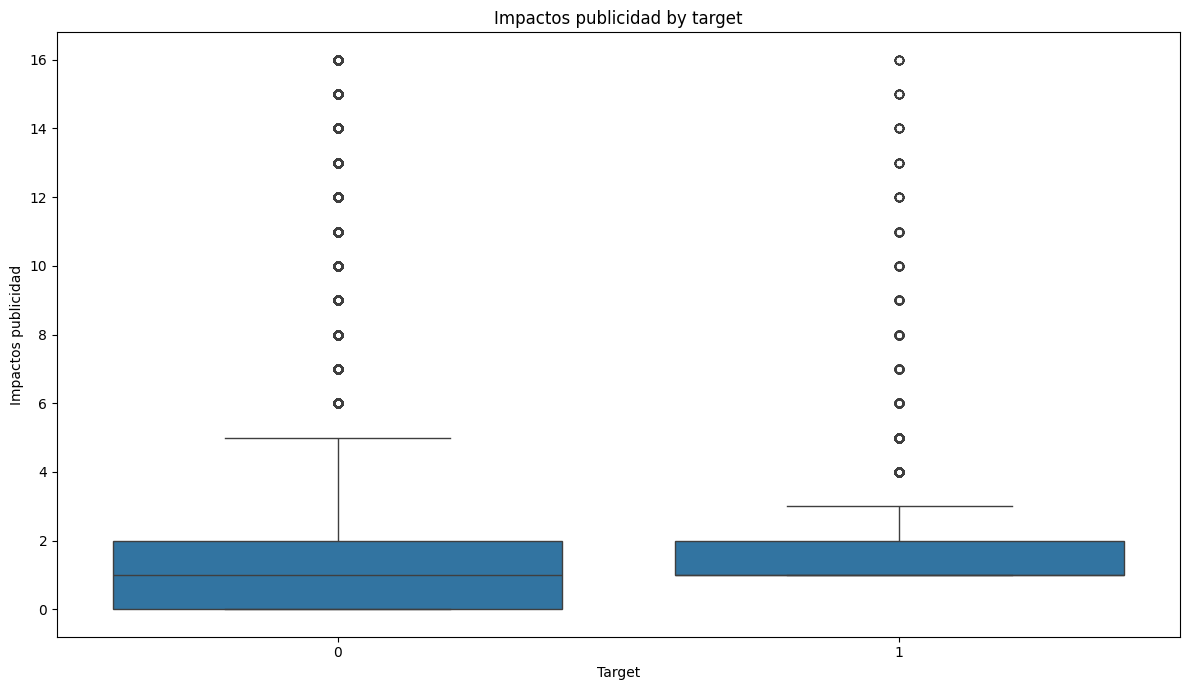

In [198]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 7))

sns.boxplot(
    data=df,
    x="target",
    y="impactos_publicidad"
)

plt.xlabel("Target")
plt.ylabel("Advertising impacts")
plt.title("Advertising impacts by target")

plt.tight_layout()
plt.show()

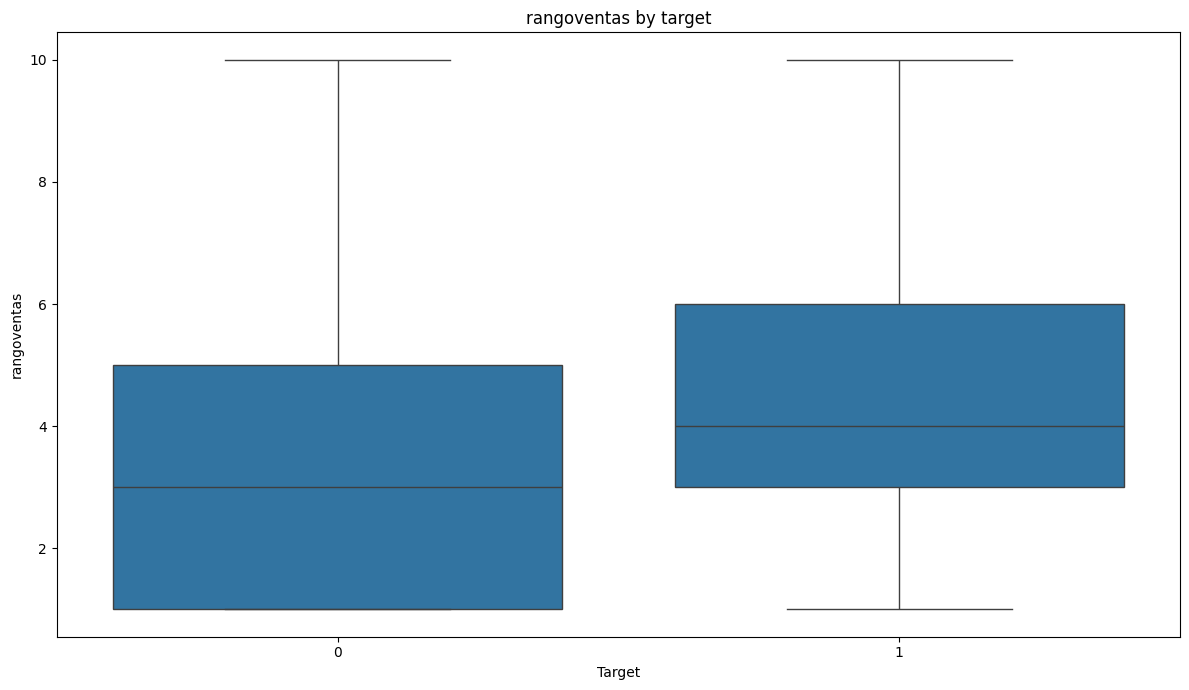

In [210]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 7))

sns.boxplot(
    data=df,
    x="target",
    y="rangoventas"
)

plt.xlabel("Target")
plt.ylabel("Sales range")
plt.title("Sales range by target")

plt.tight_layout()
plt.show()

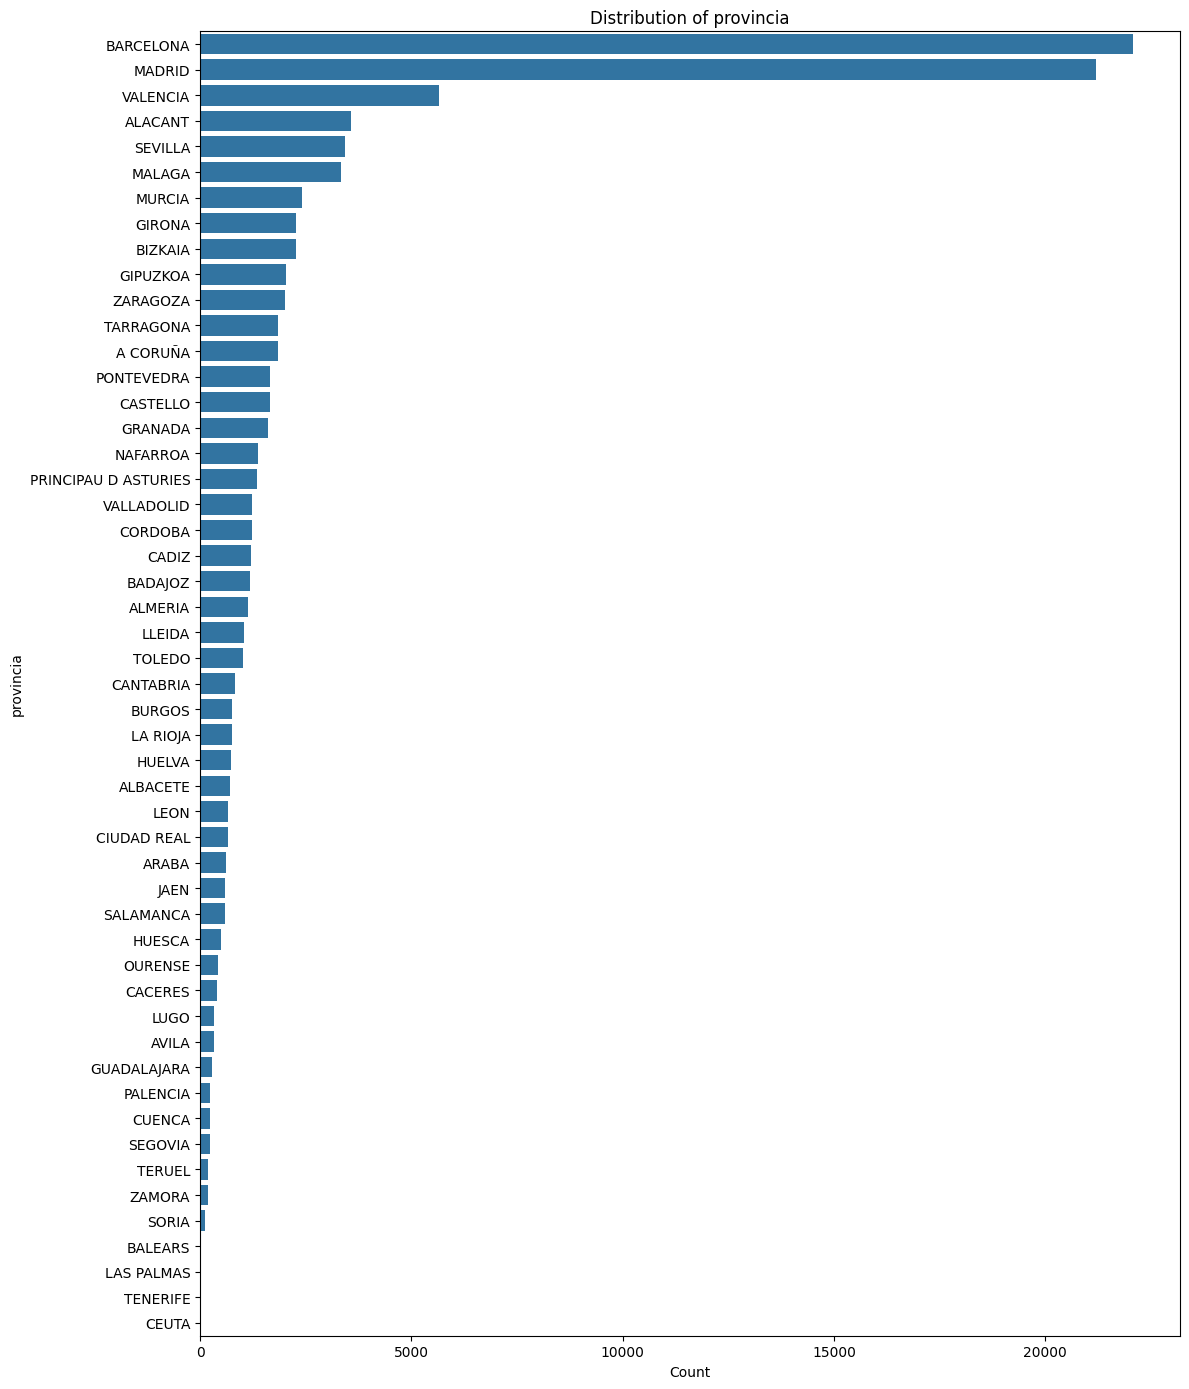

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

category_col = "provincia"

order = df[category_col].value_counts().index

plt.figure(figsize=(12, 14))

sns.countplot(
    data=df,
    y=category_col,
    order=order
)

plt.xlabel("Count")
plt.ylabel(category_col)
plt.title(f"Distribution of {category_col}")

plt.tight_layout()
plt.show()

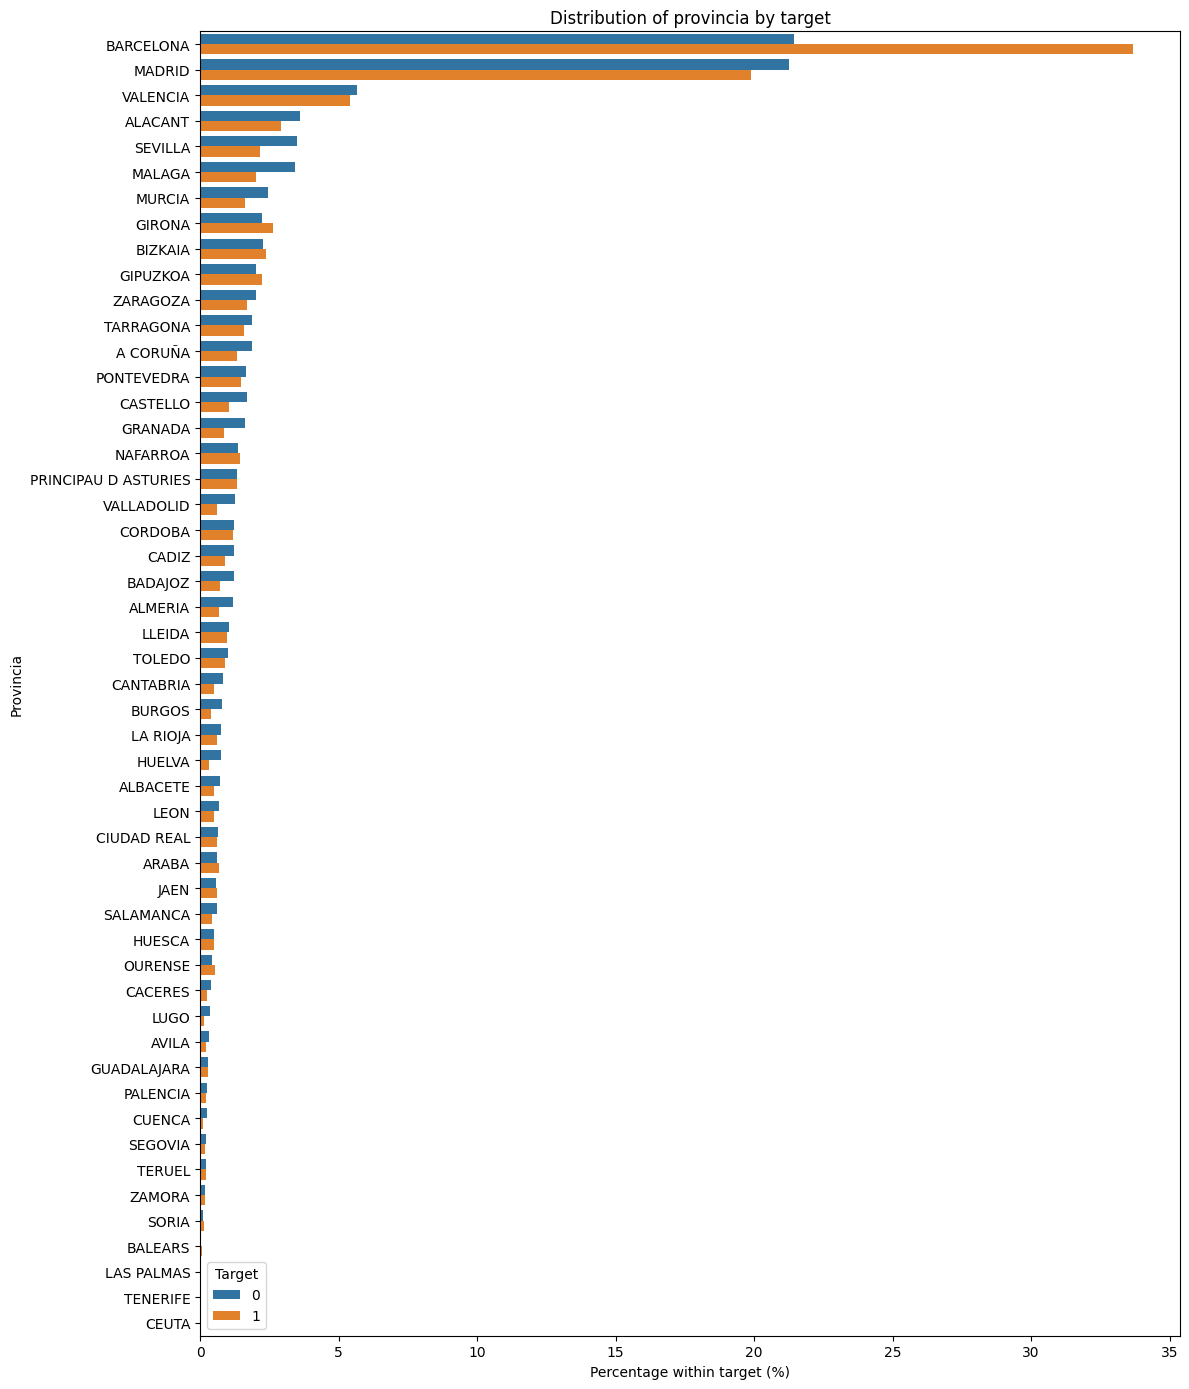

In [209]:
distribution = (
    df.groupby("target")["provincia"]
      .value_counts(normalize=True)
      .mul(100)
      .rename("percentage")
      .reset_index()
)

order = df["provincia"].value_counts().index

plt.figure(figsize=(12, 14))

sns.barplot(
    data=distribution,
    y="provincia",
    x="percentage",
    hue="target",
    order=order
)

plt.xlabel("Percentage within target (%)")
plt.ylabel("Province")
plt.title("Distribution of province by target")
plt.legend(title="Target")

plt.tight_layout()
plt.show()

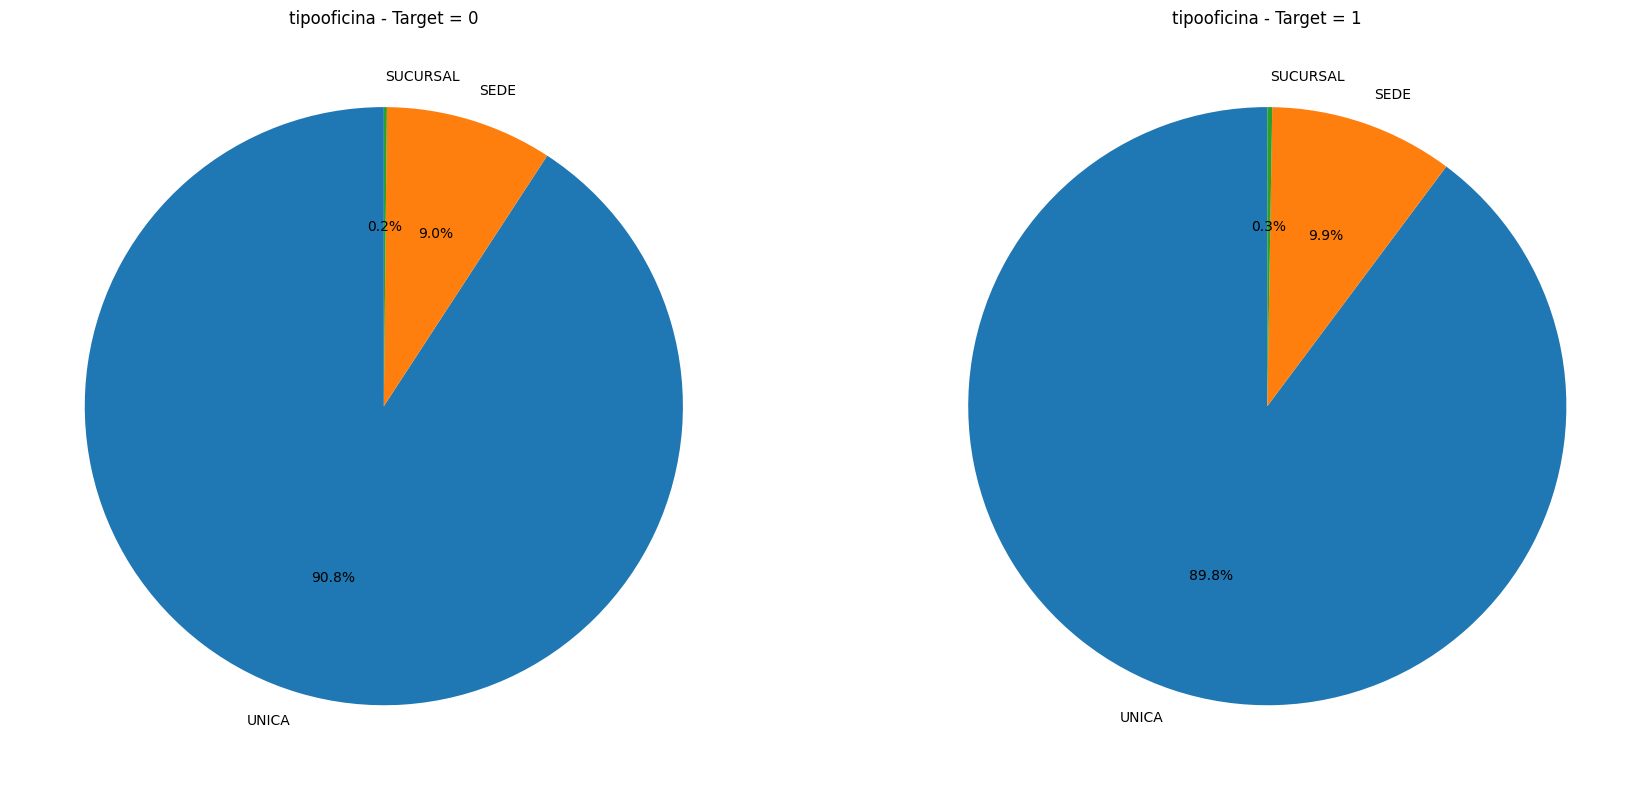

In [208]:
import matplotlib.pyplot as plt

category_col = "tipooficina"

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

for target, ax in zip([0, 1], axes):

    counts = (
        df.loc[df["target"] == target, category_col]
        .value_counts()
    )

    ax.pie(
        counts.values,
        labels=counts.index,
        autopct="%1.1f%%",
        startangle=90
    )

    ax.set_title(f"{category_col} - Target = {target}")

plt.tight_layout()
plt.show()

# Preprocessing

In [71]:
print(df.tipo_empresa.unique())
print(df.tipo_empresa.value_counts())

['E' 'O']
tipo_empresa
E    99688
O      312
Name: count, dtype: int64


In [73]:
df["anyofundacion"] = pd.to_datetime(
    df["anyofundacion"],
    format="%d/%m/%Y",
    errors="coerce"
)

print(df["anyofundacion"].min())
print(df["anyofundacion"].max())

1900-01-13 00:00:00
2019-12-15 00:00:00


In [74]:
df["observation_date"] = pd.to_datetime("2024-01-01")

# For interpretability
df["company_age_years"] = (
    df["observation_date"] - df["anyofundacion"]
).dt.days / 365.25

df.drop(columns=["observation_date","anyofundacion"], inplace = True)

In [75]:
df.head()

,tipo_empresa,codpostal,municipio,provincia,comunidadautonoma,capitalpueblo,enpoligono,habitantes_municipio,tipo_de_zona,actcnae,mercado,cnae_mercado,rangoventas,rangoempleados,numoficinas,tipooficina,nse,tendenciaempleados,tendenciaingresos,flotaturismos,flotafurgonetas,flotacamiones,flotaautobuses,riesgo,universo,existe_import,existe_export,existe_importexport,existe_email,es_ecommerce,impactos_publicidad,target,company_age_years
0,E,46008,VALENCIA,VALENCIA,COMUNITAT VALENCIANA,CAPITAL,0,786189,7,PINTURA Y ACRISTALAMIENTO,CONSTRUCCION Y OBRAS PUBLICAS,CONSTRUCCION,7.0,125.0,NaN,SEDE,4,POSITIVA LINEAL,POSITIVA NO LINEAL,0,0,0,0,NaN,ACTIVEBUSINESS,0,0,0,1,0,3,1,34.420260
1,E,28049,MADRID,MADRID,MADRID,CAPITAL,0,3141991,7,OTROS SERVICIOS RELACIONADOS CON LAS TECNOLOGÍ...,TELECOMUNICACIONES,INFORMACION Y COMUNICACIONES,1.0,NaN,NaN,SEDE,3,NaN,NaN,0,0,0,0,NaN,MARKETBASE,0,0,0,1,0,2,1,11.611225
2,E,8172,SANT CUGAT DEL VALLÈS,BARCELONA,CATALUNYA,PUEBLO,0,87830,5,PELUQUERÍA Y OTROS TRATAMIENTOS DE BELLEZA,COSMETICA Y CUIDADO PERSONAL,OTROS SERVICIOS,7.0,135.0,NaN,SEDE,5,POSITIVA LINEAL,POSITIVA LINEAL,0,0,0,0,NaN,ACTIVEBUSINESS,0,0,0,1,0,3,1,24.999316
3,E,8011,BARCELONA,BARCELONA,CATALUNYA,CAPITAL,0,1604555,7,COMERCIO AL POR MAYOR DE TEXTILES,TEXTIL Y CONFECCION,COMERCIO AL POR MAYOR Y AL POR MENOR; REPARACI...,6.0,100.0,NaN,SEDE,5,NaN,NaN,0,0,0,0,NaN,ACTIVEBUSINESS,0,0,0,0,0,1,1,8.919918
4,E,28031,MADRID,MADRID,MADRID,CAPITAL,1,3141991,7,OTRAS ACTIVIDADES DE IMPRESIÓN Y ARTES GRÁFICAS,ARTES GRAFICAS,INDUSTRIA MANUFACTURERA,4.0,120.0,NaN,SEDE,0,POSITIVA NO LINEAL,POSITIVA LINEAL,0,0,0,0,NaN,ACTIVEBUSINESS,0,0,0,0,0,5,1,10.261465


In [76]:
variable_with_nan = []

for col in df.columns:
    if df[col].isna().mean() > 0:
        variable_with_nan.append(col)

nan_by_target = (
    df.groupby("target")[variable_with_nan]
      .apply(lambda x: x.isna().mean() * 100)
      .T
)

nan_by_target.columns = ["target_0", "target_1"]

nan_by_target["difference"] = (
    nan_by_target["target_1"] - nan_by_target["target_0"]
)

nan_by_target["abs_difference"] = nan_by_target["difference"].abs()

nan_by_target = nan_by_target.sort_values(
    "abs_difference",
    ascending=False
)

nan_by_target

,target_0,target_1,difference,abs_difference
tendenciaingresos,63.020206,45.907541,-17.112666,17.112666
tendenciaempleados,54.497371,41.530883,-12.966488,12.966488
company_age_years,9.166825,6.081849,-3.084976,3.084976
rangoempleados,4.161652,1.174687,-2.986965,2.986965
numoficinas,4.166931,2.027283,-2.139648,2.139648
riesgo,99.344397,99.867374,0.522977,0.522977
universo,0.013724,0.000000,-0.013724,0.013724
actcnae,0.010557,0.000000,-0.010557,0.010557
mercado,0.010557,0.000000,-0.010557,0.010557
rangoventas,0.001056,0.000000,-0.001056,0.001056


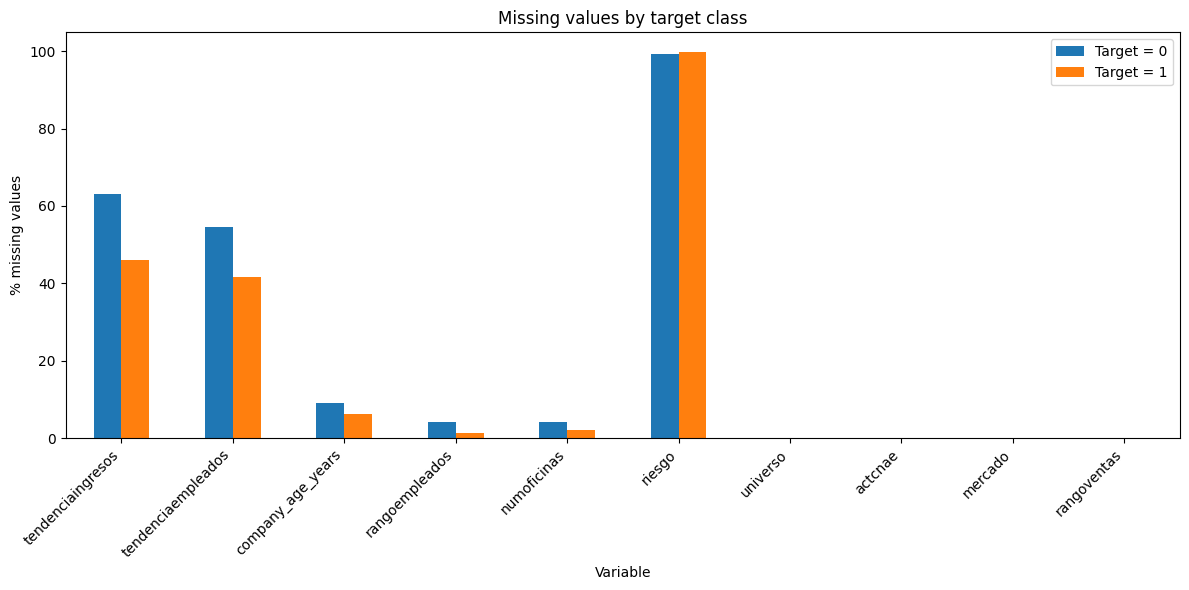

In [77]:
nan_by_target[["target_0", "target_1"]].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.ylabel("% missing values")
plt.xlabel("Variable")
plt.title("Missing values by target class")
plt.xticks(rotation=45, ha="right")
plt.legend(["Target = 0", "Target = 1"])
plt.tight_layout()
plt.show()


In [78]:
df.dropna(subset=["universo","actcnae","mercado","rangoventas"], inplace = True)
df.drop(columns=["riesgo"], inplace=True)
df.head()

,tipo_empresa,codpostal,municipio,provincia,comunidadautonoma,capitalpueblo,enpoligono,habitantes_municipio,tipo_de_zona,actcnae,mercado,cnae_mercado,rangoventas,rangoempleados,numoficinas,tipooficina,nse,tendenciaempleados,tendenciaingresos,flotaturismos,flotafurgonetas,flotacamiones,flotaautobuses,universo,existe_import,existe_export,existe_importexport,existe_email,es_ecommerce,impactos_publicidad,target,company_age_years
0,E,46008,VALENCIA,VALENCIA,COMUNITAT VALENCIANA,CAPITAL,0,786189,7,PINTURA Y ACRISTALAMIENTO,CONSTRUCCION Y OBRAS PUBLICAS,CONSTRUCCION,7.0,125.0,NaN,SEDE,4,POSITIVA LINEAL,POSITIVA NO LINEAL,0,0,0,0,ACTIVEBUSINESS,0,0,0,1,0,3,1,34.420260
1,E,28049,MADRID,MADRID,MADRID,CAPITAL,0,3141991,7,OTROS SERVICIOS RELACIONADOS CON LAS TECNOLOGÍ...,TELECOMUNICACIONES,INFORMACION Y COMUNICACIONES,1.0,NaN,NaN,SEDE,3,NaN,NaN,0,0,0,0,MARKETBASE,0,0,0,1,0,2,1,11.611225
2,E,8172,SANT CUGAT DEL VALLÈS,BARCELONA,CATALUNYA,PUEBLO,0,87830,5,PELUQUERÍA Y OTROS TRATAMIENTOS DE BELLEZA,COSMETICA Y CUIDADO PERSONAL,OTROS SERVICIOS,7.0,135.0,NaN,SEDE,5,POSITIVA LINEAL,POSITIVA LINEAL,0,0,0,0,ACTIVEBUSINESS,0,0,0,1,0,3,1,24.999316
3,E,8011,BARCELONA,BARCELONA,CATALUNYA,CAPITAL,0,1604555,7,COMERCIO AL POR MAYOR DE TEXTILES,TEXTIL Y CONFECCION,COMERCIO AL POR MAYOR Y AL POR MENOR; REPARACI...,6.0,100.0,NaN,SEDE,5,NaN,NaN,0,0,0,0,ACTIVEBUSINESS,0,0,0,0,0,1,1,8.919918
4,E,28031,MADRID,MADRID,MADRID,CAPITAL,1,3141991,7,OTRAS ACTIVIDADES DE IMPRESIÓN Y ARTES GRÁFICAS,ARTES GRAFICAS,INDUSTRIA MANUFACTURERA,4.0,120.0,NaN,SEDE,0,POSITIVA NO LINEAL,POSITIVA LINEAL,0,0,0,0,ACTIVEBUSINESS,0,0,0,0,0,5,1,10.261465


In [79]:
df.municipio.value_counts()

municipio
MADRID               12393
BARCELONA             9183
VALENCIA              2267
SEVILLA               1610
MÁLAGA                1460
                     ...  
ABUSEJO                  1
ARMAÑANZAS               1
HERRERÍAS                1
CASAS ALTAS              1
HINOJOSA DE DUERO        1
Name: count, Length: 3992, dtype: int64

In [80]:
# itll be enough with the province
df.drop(columns=["municipio","codpostal","comunidadautonoma"], inplace = True)

In [81]:
df.tipooficina.unique()

array(['SEDE', 'UNICA', 'SUCURSAL'], dtype=object)

In [82]:
cat_cols = ["actcnae", "mercado", "cnae_mercado"]
target = "target"

for col in cat_cols:
    print(f"\n--- {col} ---")
    print("Unique values:", df[col].nunique())
    print(df[col].value_counts(normalize=True, dropna=False).head(20))


--- actcnae ---
Unique values: 562
actcnae
COMERCIO AL POR MAYOR E INTERMEDIARIOS DEL COMERCIO, EXCEPTO DE VEHÍCULOS DE MOTOR Y MOTOCICLETAS                                  0.029324
AGENTES DE LA PROPIEDAD INMOBILIARIA                                                                                               0.027524
PELUQUERÍA Y OTROS TRATAMIENTOS DE BELLEZA                                                                                         0.025044
INSTALACIONES ELÉCTRICAS                                                                                                           0.023373
AGENCIAS DE PUBLICIDAD                                                                                                             0.021263
COMERCIO AL POR MAYOR DE PRODUCTOS ALIMENTICIOS, BEBIDAS Y TABACO                                                                  0.020553
SERVICIOS TÉCNICOS DE INGENIERÍA Y OTRAS ACTIVIDADES RELACIONADAS CON EL ASESORAMIENTO TÉCNICO                      

In [ ]:
df.drop(columns=["actcnae","mercado"], inplace = True)
df.drop(columns=["id"], inplace = True)

In [84]:
df.columns

Index(['tipo_empresa', 'provincia', 'capitalpueblo', 'enpoligono',
       'habitantes_municipio', 'tipo_de_zona', 'cnae_mercado', 'rangoventas',
       'rangoempleados', 'numoficinas', 'tipooficina', 'nse',
       'tendenciaempleados', 'tendenciaingresos', 'flotaturismos',
       'flotafurgonetas', 'flotacamiones', 'flotaautobuses', 'universo',
       'existe_import', 'existe_export', 'existe_importexport', 'existe_email',
       'es_ecommerce', 'impactos_publicidad', 'target', 'company_age_years'],
      dtype='object')

# Models

## Split

In [129]:
target_col = "target"
baseline_drop_cols = ["tendenciaempleados", "tendenciaingresos"]

# ============================================================
# Shared stratified split (same train/val/test for both models)
# ============================================================

X = df.drop(columns=[target_col])
y = df[target_col]

# 70% Train / 30% Temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# 15% Validation / 15% Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

# Baseline uses the same rows; drops high-missing tendencia columns only.
# Remaining NaNs are imputed inside the baseline Pipeline (fit on train).
X_train_clean = X_train.drop(columns=baseline_drop_cols)
X_test_clean = X_test.drop(columns=baseline_drop_cols)
y_train_clean = y_train
y_test_clean = y_test

assert X_test_clean.index.equals(X_test.index), "Baseline and XGBoost test indices must match"

# ============================================================
# Check shared splits
# ============================================================

print("Train shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)
print("Baseline train/test shapes:", X_train_clean.shape, X_test_clean.shape)

print("\nTrain target distribution:")
print(y_train.value_counts(normalize=True))

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True))


Train shape: (69990, 26)
Validation shape: (14998, 26)
Test shape: (14998, 26)
Baseline train/test shapes: (69990, 24) (14998, 24)

Train target distribution:
target
0    0.947207
1    0.052793
Name: proportion, dtype: float64

Validation target distribution:
target
0    0.947193
1    0.052807
Name: proportion, dtype: float64

Test target distribution:
target
0    0.94726
1    0.05274
Name: proportion, dtype: float64


In [130]:
# Baseline feature set (same indices as X_train / X_test)
print("Dropped for baseline:", baseline_drop_cols)
print("Shared test index match:", X_test_clean.index.equals(X_test.index))
X_train_clean.columns.tolist()


Dropped for baseline: ['tendenciaempleados', 'tendenciaingresos']
Shared test index match: True


['tipo_empresa',
 'provincia',
 'capitalpueblo',
 'enpoligono',
 'habitantes_municipio',
 'tipo_de_zona',
 'cnae_mercado',
 'rangoventas',
 'rangoempleados',
 'numoficinas',
 'tipooficina',
 'nse',
 'flotaturismos',
 'flotafurgonetas',
 'flotacamiones',
 'flotaautobuses',
 'universo',
 'existe_import',
 'existe_export',
 'existe_importexport',
 'existe_email',
 'es_ecommerce',
 'impactos_publicidad',
 'company_age_years']

In [131]:
print("Full feature count (XGBoost):", X_train.shape[1])
print("Baseline feature count:", X_train_clean.shape[1])


Full feature count (XGBoost): 26
Baseline feature count: 24


In [132]:
def eval_metric(y_pred, y_true, cost=10, benefit=2000):
    tp = ((y_pred == 1) & (y_true == 1)).sum()
    fp = ((y_pred == 1) & (y_true == 0)).sum()

    return tp * benefit - (tp + fp) * cost

## Baseline 

In [133]:
categorical_cols = X_train_clean.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_cols = X_train_clean.select_dtypes(
    include="number"
).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]),
            numeric_cols
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore")),
            ]),
            categorical_cols
        )
    ]
)

baseline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

baseline.fit(
    X_train_clean,
    y_train_clean
)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['enpoligono',
                                                   'habitantes_municipio',
                                                   'tipo_de_zona',
                                                   'rangoventas',
                                                   'rangoempleados',
                                                   'numoficinas', 'nse',
                                                   'flotaturismos',
                                                   'flotafurgonetas',
                                                   'flotacamiones',
                                                   'flotaautobuses',
                                                   'existe_import...
                                                   'impactos_publicidad',
                                                   'company_age_years']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['tipo_empresa', 'provincia',
                                                   'capitalpueblo',
                                                   'cnae_mercado',
                                                   'tipooficina',
                                                   'universo'])])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [134]:
y_pred = baseline.predict(X_test_clean)
y_proba = baseline.predict_proba(X_test_clean)[:, 1]

print(classification_report(y_test_clean, y_pred))

print(
    "ROC-AUC:",
    roc_auc_score(y_test_clean, y_proba)
)

print(
    "PR-AUC:",
    average_precision_score(y_test_clean, y_proba)
)

baseline_metrics = {
    "dataset": "shared",
    "features": "no_tendencia",
    "split": "test",
    "threshold": 0.5,
    "f1": float(f1_score(y_test_clean, y_pred)),
    "precision": float(precision_score(y_test_clean, y_pred)),
    "recall": float(recall_score(y_test_clean, y_pred)),
    "accuracy": float(accuracy_score(y_test_clean, y_pred)),
    "roc_auc": float(roc_auc_score(y_test_clean, y_proba)),
    "pr_auc": float(average_precision_score(y_test_clean, y_proba)),
    "eval_metric": float(eval_metric(y_pred, y_test_clean)),
}


              precision    recall  f1-score   support

           0       0.97      0.68      0.80     14207
           1       0.10      0.66      0.18       791

    accuracy                           0.68     14998
   macro avg       0.54      0.67      0.49     14998
weighted avg       0.93      0.68      0.77     14998

ROC-AUC: 0.7347809438857665
PR-AUC: 0.1315928626409587


## XGBoost 

In [135]:
new_grid_search = False

In [136]:
categorical_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns

for col in categorical_cols:
    X_train[col] = X_train[col].astype("category")
    X_val[col] = X_val[col].astype("category")
    X_test[col] = X_test[col].astype("category")


# ============================================================
# Base XGBoost model
# ============================================================

xgb = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    enable_categorical=True,
    random_state=42,
    n_jobs=1
)

# ============================================================
# Parameter grid
# ============================================================
ratio = (y_train == 0).sum() / (y_train == 1).sum()

param_grid = {
    "n_estimators": [200, 400],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.03, 0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
    "min_child_weight": [1, 5],
    "gamma": [0, 0.1],
    "scale_pos_weight": [1, ratio]
}

# ============================================================
# Stratified CV
# ============================================================

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# ============================================================
# Grid search
# ============================================================

if new_grid_search:
    search_xgb = GridSearchCV(
        estimator=xgb,
        param_grid=param_grid,
        scoring="average_precision",   # PR-AUC
        cv=cv,
        n_jobs=-1,
        verbose=2,
        refit=True,
        return_train_score=True
    )

    search_xgb.fit(
        X_train,
        y_train
    )

    best_params = search_xgb.best_params_
    
    with open("reports/best_xgb_params.json", "w") as f:
        json.dump(best_params, f, indent=4)
else:
    with open("reports/best_xgb_params.json", "r") as f:
        best_params = json.load(f)


In [137]:
print("Best parameters:")
print(best_params)

Best parameters:
{'colsample_bytree': 0.8, 'gamma': 0.1, 'learning_rate': 0.05, 'max_depth': 3, 'min_child_weight': 5, 'n_estimators': 400, 'scale_pos_weight': 1, 'subsample': 1.0}


In [138]:
#best_params["scale_pos_weight"] = ratio

xgb_final = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    enable_categorical=True,
    random_state=42,
    n_jobs=-1,
    **best_params
)

xgb_final.fit(X_train, y_train)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=0.1,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=5, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=400, n_jobs=-1,
              num_parallel_tree=None, ...)

In [139]:
# Default-threshold (0.5) scores on TEST; threshold tuned on validation next
y_test_proba = xgb_final.predict_proba(X_test)[:, 1]
y_test_pred_default = xgb_final.predict(X_test)

print("XGBoost @ default threshold 0.5 (TEST)")
print("Accuracy:", accuracy_score(y_test, y_test_pred_default))
print("ROC-AUC:", roc_auc_score(y_test, y_test_proba))
print("PR-AUC:", average_precision_score(y_test, y_test_proba))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_default))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_default))


XGBoost @ default threshold 0.5 (TEST)
Accuracy: 0.9720629417255634
ROC-AUC: 0.9305518539898202
PR-AUC: 0.6786099211286083

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.99     14207
           1       0.99      0.47      0.64       791

    accuracy                           0.97     14998
   macro avg       0.98      0.74      0.81     14998
weighted avg       0.97      0.97      0.97     14998


Confusion Matrix:
[[14205     2]
 [  417   374]]


In [147]:
import numpy as np
from sklearn.metrics import precision_recall_curve

# Predicted probabilities for class 1
y_val_proba = xgb_final.predict_proba(X_val)[:, 1]

# Precision-recall values at different thresholds
precision, recall, thresholds = precision_recall_curve(
    y_val,
    y_val_proba
)

# Calculate campaign profit for each threshold
profit_scores = []

for threshold in thresholds:
    y_val_pred = (y_val_proba >= threshold).astype(int)

    profit = eval_metric(
        y_val_pred,
        y_val,
        cost=10,
        benefit=200
    )

    profit_scores.append(profit)

profit_scores = np.array(profit_scores)

# Find threshold with maximum profit
best_idx = np.argmax(profit_scores)
best_threshold = thresholds[best_idx]

# Predictions using optimal threshold
y_val_pred = (y_val_proba >= best_threshold).astype(int)

print("Best threshold:", best_threshold)
print("Best profit:", profit_scores[best_idx])
print("Precision:", precision[best_idx])
print("Recall:", recall[best_idx])
print("Companies targeted:", y_val_pred.sum())

Best threshold: 0.04366484
Best profit: 108330
Precision: 0.22102936532996525
Recall: 0.8838383838383839
Companies targeted: 3167


In [157]:
y_val_pred = (y_val_proba >= best_threshold).astype(int)

print("Threshold:", best_threshold)
print("Accuracy:", accuracy_score(y_val, y_val_pred))
print("Precision:", precision_score(y_val, y_val_pred))
print("Recall:", recall_score(y_val, y_val_pred))
print("F1:", f1_score(y_val, y_val_pred))

print("\nClassification report:")
print(classification_report(y_val, y_val_pred))

print("\nConfusion matrix:")
print(confusion_matrix(y_val, y_val_pred))


Threshold: 0.04366484
Accuracy: 0.8293772503000401
Precision: 0.22102936532996525
Recall: 0.8838383838383839
F1: 0.35362465269007326

Classification report:
              precision    recall  f1-score   support

           0       0.99      0.83      0.90     14206
           1       0.22      0.88      0.35       792

    accuracy                           0.83     14998
   macro avg       0.61      0.86      0.63     14998
weighted avg       0.95      0.83      0.87     14998


Confusion matrix:
[[11739  2467]
 [   92   700]]


In [158]:
# Final XGBoost metrics on the SAME TEST indices as baseline
y_test_pred = (y_test_proba >= best_threshold).astype(int)

xgboost_metrics = {
    "dataset": "shared",
    "features": "full_features",
    "split": "test",
    "threshold": float(best_threshold),
    "f1": float(f1_score(y_test, y_test_pred)),
    "precision": float(precision_score(y_test, y_test_pred)),
    "recall": float(recall_score(y_test, y_test_pred)),
    "accuracy": float(accuracy_score(y_test, y_test_pred)),
    "roc_auc": float(roc_auc_score(y_test, y_test_proba)),
    "pr_auc": float(average_precision_score(y_test, y_test_proba)),
    "eval_metric": float(eval_metric(y_test_pred, y_test)),
}

metrics = {
    "baseline_logistic": baseline_metrics,
    "xgboost": xgboost_metrics,
}

with open("reports/metrics_comparison.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=4)

print("Saved reports/metrics_comparison.json")
assert X_test_clean.index.equals(X_test.index)
pd.DataFrame(metrics).T


Saved metrics_comparison.json


,dataset,features,split,threshold,f1,precision,recall,accuracy,roc_auc,pr_auc,eval_metric
baseline_logistic,shared,no_tendencia,test,0.5,0.180353,0.104324,0.664981,0.681224,0.734781,0.131593,1001580.0
xgboost,shared,full_features,test,0.043665,0.334846,0.209134,0.839444,0.82411,0.930552,0.67861,1296250.0


# Interpretation

In [159]:
importance_df = pd.DataFrame({
    "feature": X_train.columns,
    "importance": xgb_final.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

importance_df.head(20)


,feature,importance
6,cnae_mercado,0.297896
24,impactos_publicidad,0.215560
7,rangoventas,0.143808
18,universo,0.090677
19,existe_import,0.037980
12,tendenciaempleados,0.028442
22,existe_email,0.022336
20,existe_export,0.021447
13,tendenciaingresos,0.021231
1,provincia,0.018729


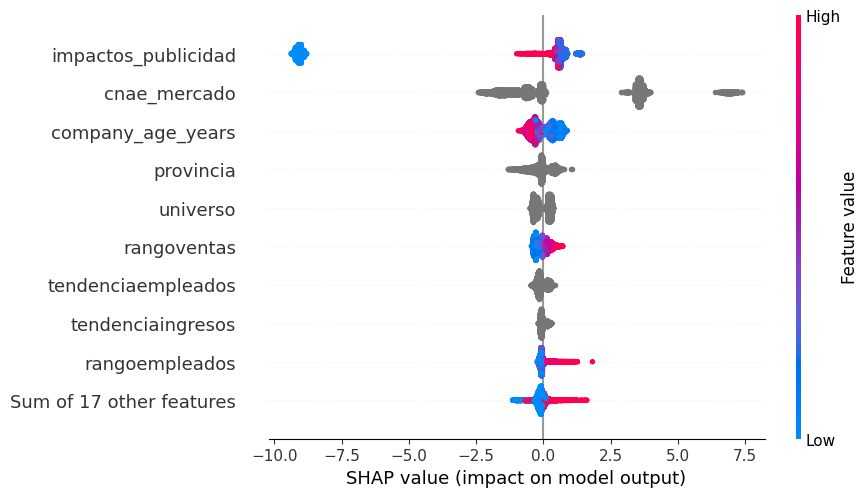

In [177]:
# Use validation data for interpretation
explainer = shap.TreeExplainer(xgb_final)

shap_values = explainer(X_val)

# SHAP summary / beeswarm plot
shap.plots.beeswarm(
    shap_values,
    max_display=10
)

In [185]:
import numpy as np
import matplotlib.pyplot as plt

# Global SHAP importance = mean absolute SHAP value
mean_abs_shap = np.abs(shap_values.values).mean(axis=0)

# Feature importance
shap_importance = pd.Series(
    mean_abs_shap,
    index=shap_values.feature_names
).sort_values(ascending=False).head(10)



In [189]:
shap_importance.index

Index(['impactos_publicidad', 'cnae_mercado', 'company_age_years', 'provincia',
       'universo', 'rangoventas', 'tendenciaempleados', 'tendenciaingresos',
       'rangoempleados', 'existe_email'],
      dtype='object')

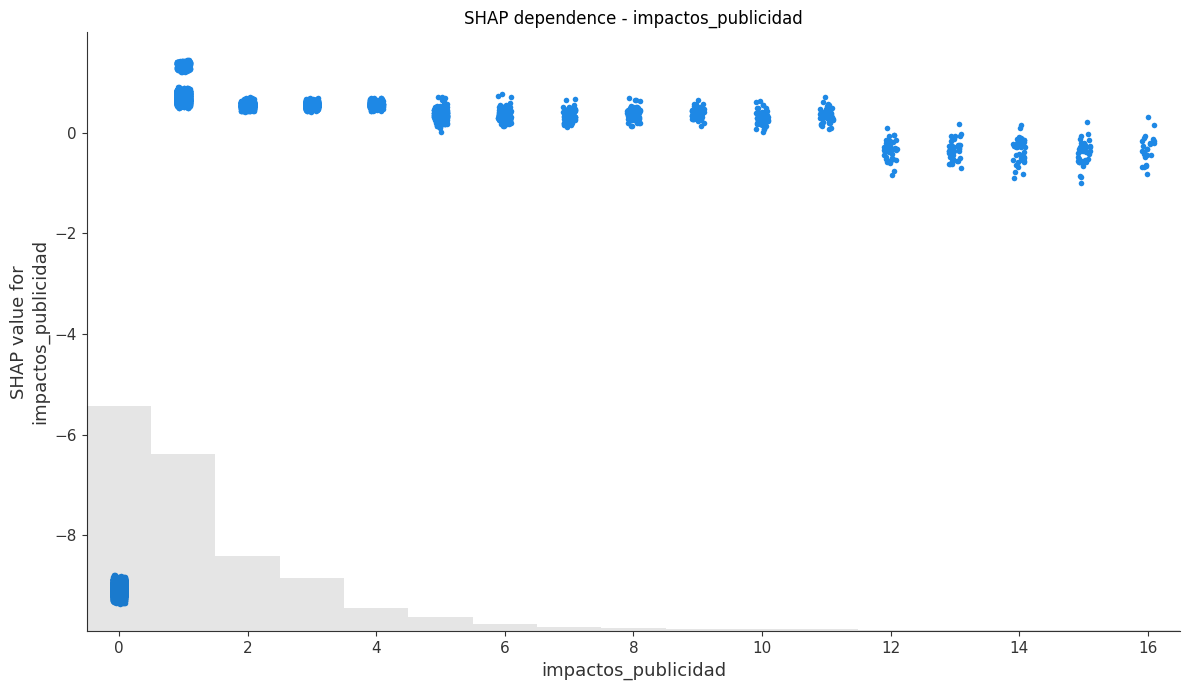

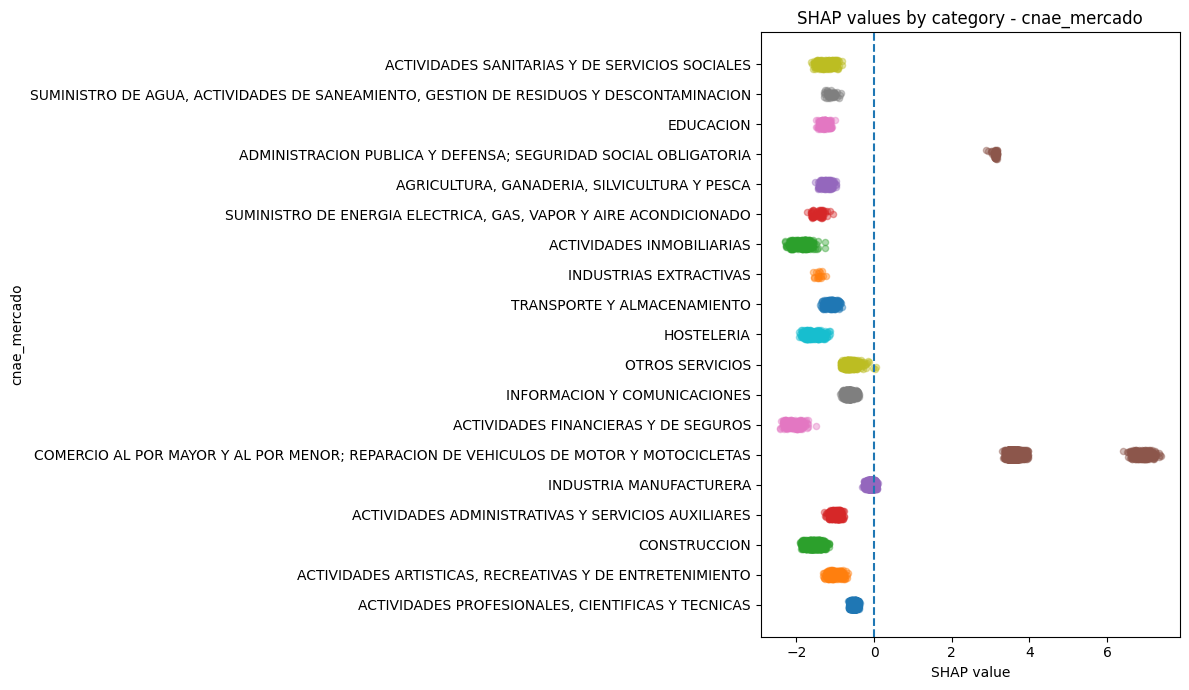

c:\Users\migue\anaconda3\Lib\site-packages\shap\plots\_scatter.py:452: RuntimeWarning: invalid value encountered in greater
  min_dist = np.min(diffs[diffs > 1e-8])


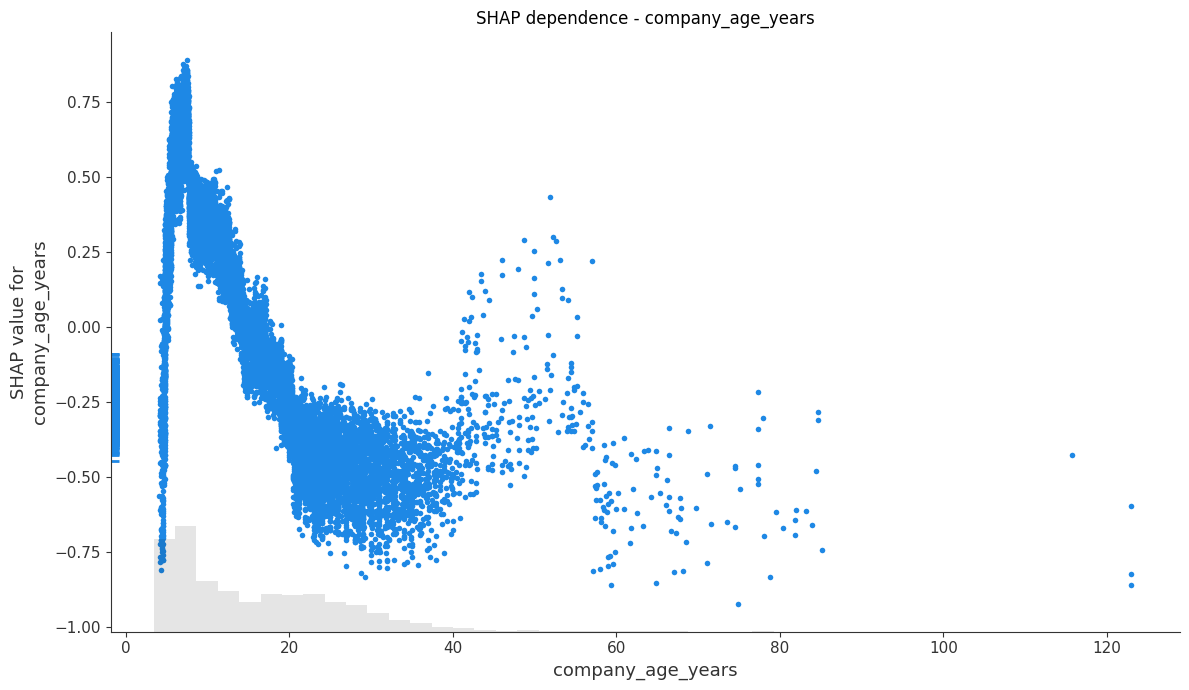

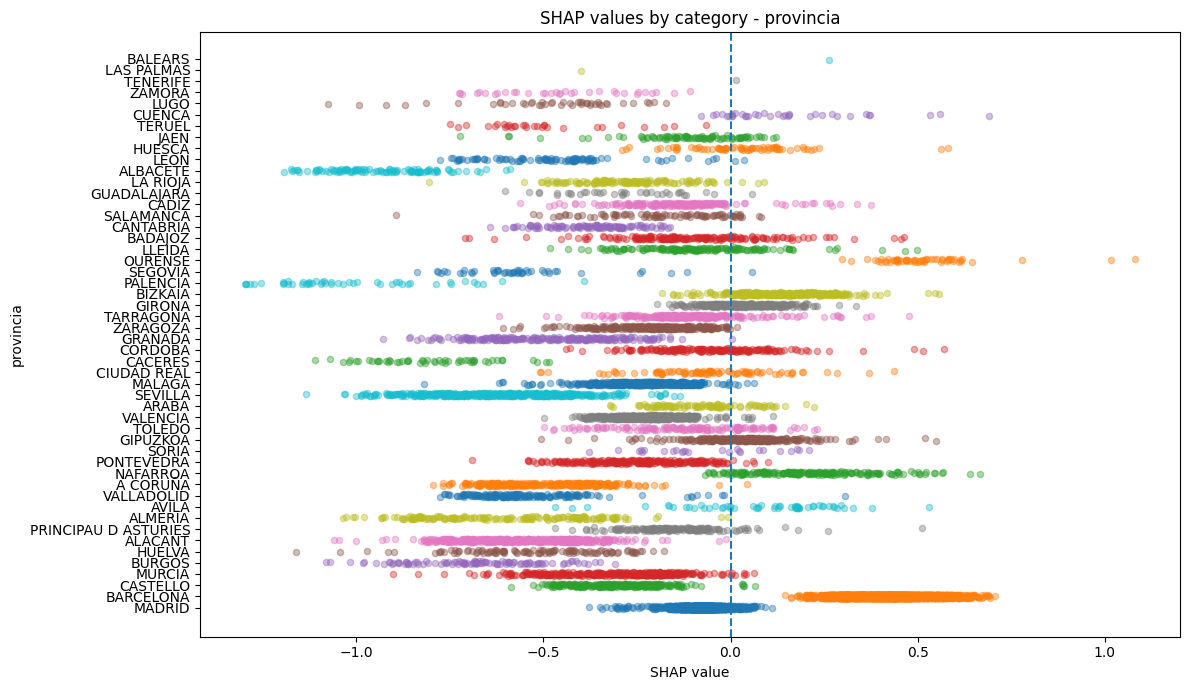

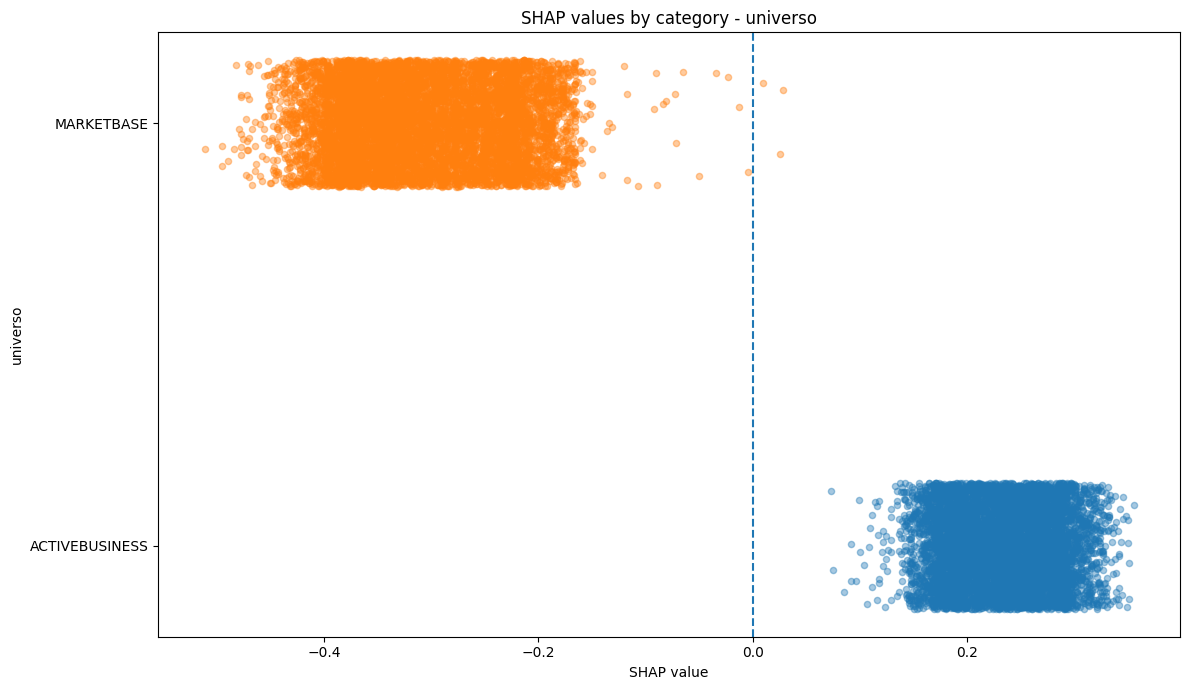

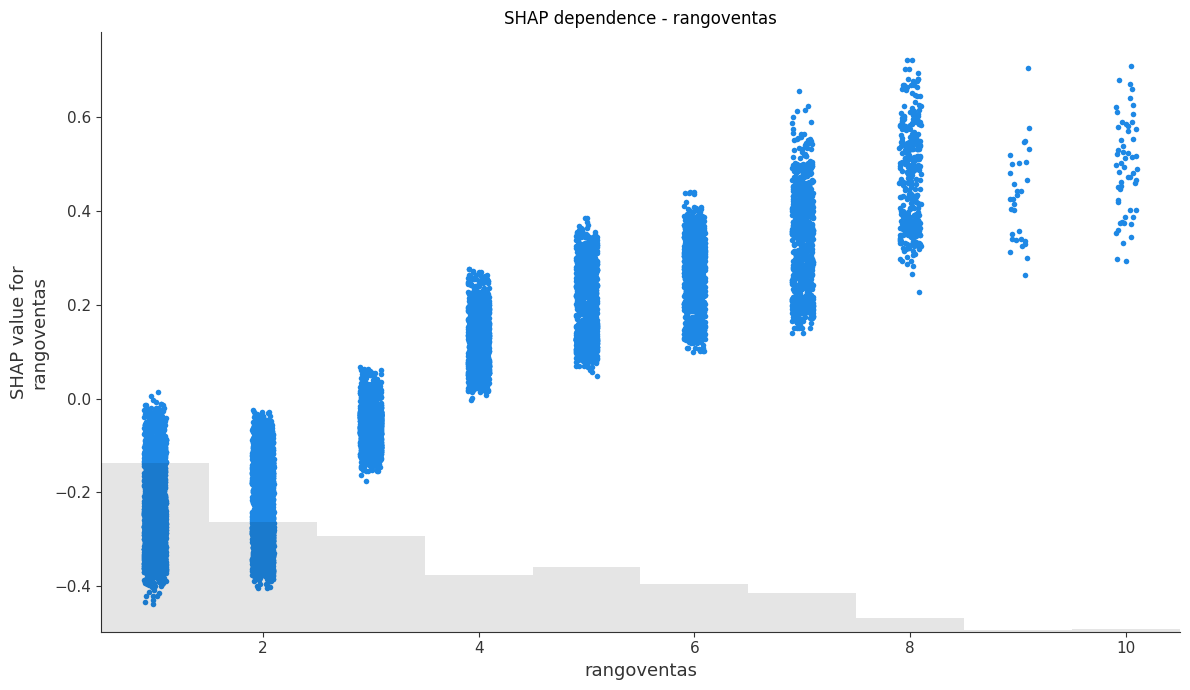

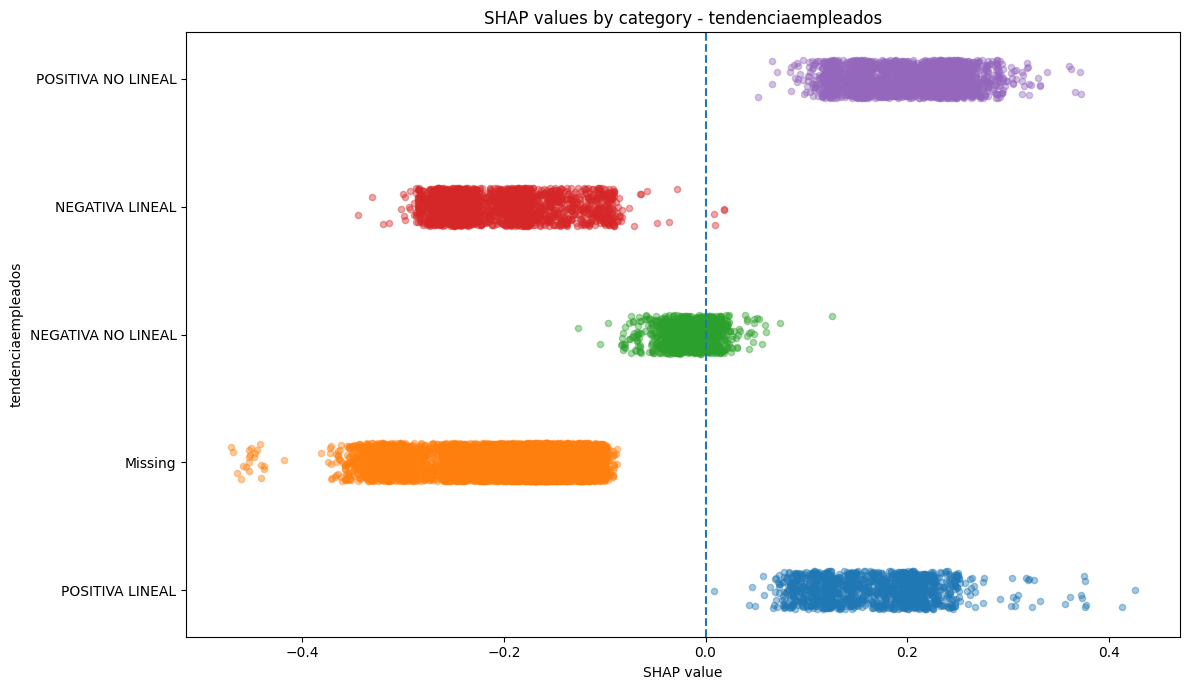

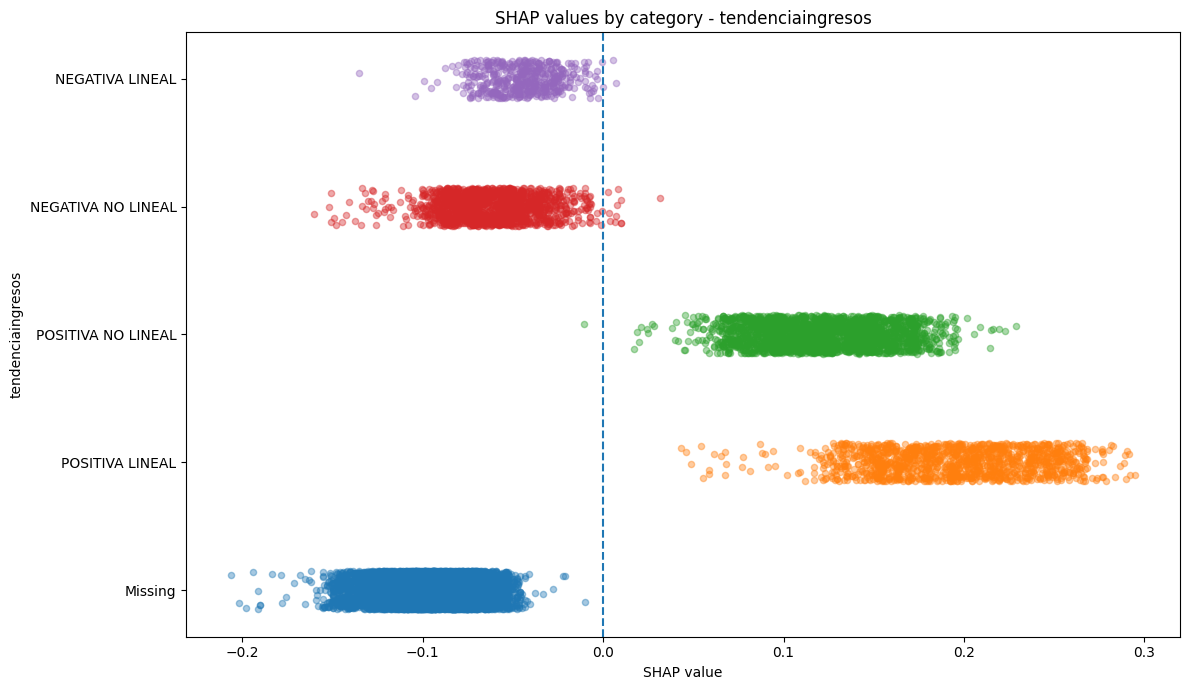

c:\Users\migue\anaconda3\Lib\site-packages\shap\plots\_scatter.py:452: RuntimeWarning: invalid value encountered in greater
  min_dist = np.min(diffs[diffs > 1e-8])


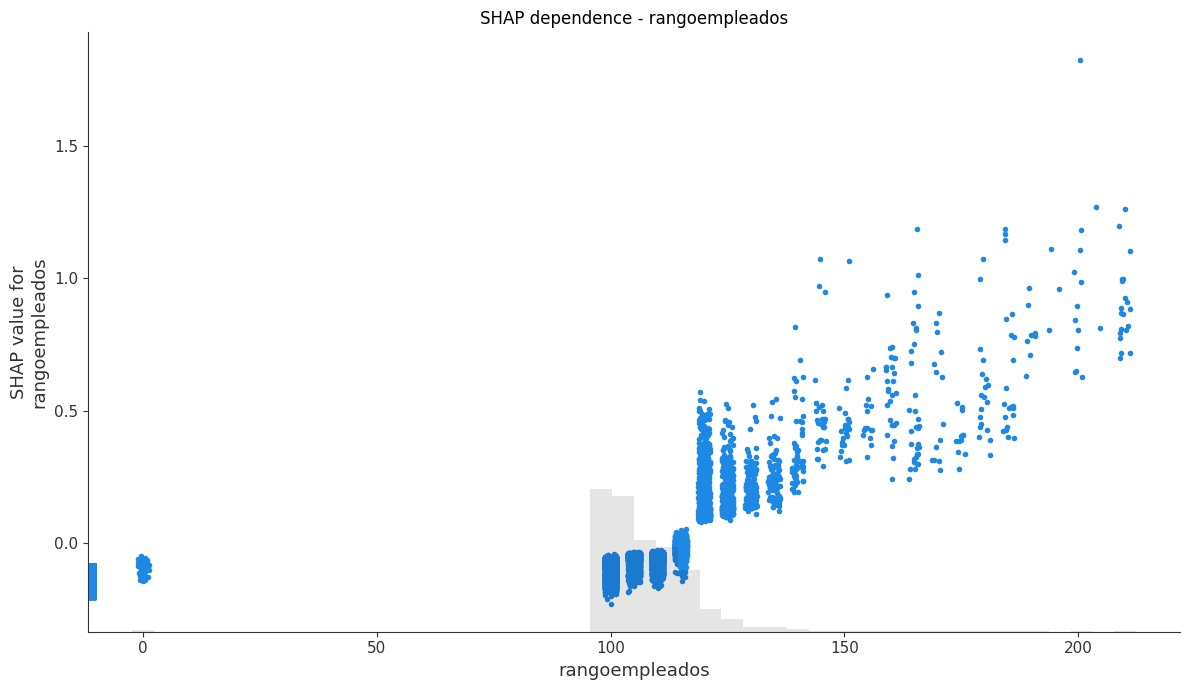

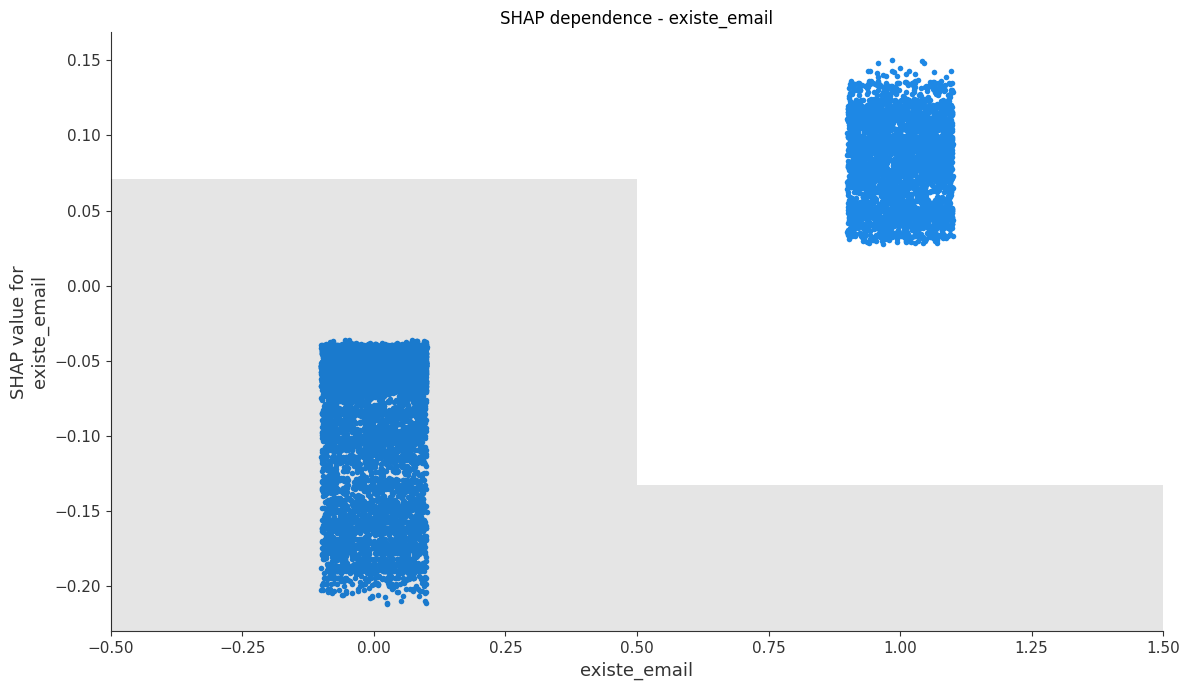

In [194]:
for feature in shap_importance.index:

    # ------------------
    # Numeric
    # ------------------
    if pd.api.types.is_numeric_dtype(X_val[feature]):

        shap.plots.scatter(
            shap_values[:, feature],
            show=False
        )

        plt.gcf().set_size_inches(12, 7)
        plt.title(f"SHAP dependence - {feature}")
        plt.tight_layout()
        plt.show()

    # ------------------
    # Categorical
    # ------------------
    else:

        plot_df = pd.DataFrame({
            "category": X_val[feature]
                .astype("object")
                .fillna("Missing")
                .astype(str),

            "shap_value": shap_values[:, feature].values
        })

        categories = plot_df["category"].unique()

        plt.figure(figsize=(12, 7))

        for i, category in enumerate(categories):

            values = plot_df.loc[
                plot_df["category"] == category,
                "shap_value"
            ]

            y = i + np.random.uniform(
                -0.15,
                0.15,
                size=len(values)
            )

            plt.scatter(
                values,
                y,
                alpha=0.4,
                s=20
            )

        plt.yticks(
            range(len(categories)),
            categories
        )

        plt.axvline(0, linestyle="--")

        plt.xlabel("SHAP value")
        plt.ylabel(feature)
        plt.title(f"SHAP values by category - {feature}")

        plt.tight_layout()
        plt.show()

In [173]:
pred = xgb_final.predict_proba(X_test)[:, 1]

results = pd.DataFrame({
    "probability": pred,
    "true_class": y_test.values
}, index=X_test.index)

top = results.sort_values(
    "probability",
    ascending=False
).head(5)

print(top)

idxs = top.index

      probability  true_class
5086     0.999444           1
4444     0.999208           1
3374     0.999130           1
1151     0.999101           1
4639     0.999067           1


In [174]:
X_test.loc[idxs]

,tipo_empresa,provincia,capitalpueblo,enpoligono,habitantes_municipio,tipo_de_zona,cnae_mercado,rangoventas,rangoempleados,numoficinas,tipooficina,nse,tendenciaempleados,tendenciaingresos,flotaturismos,flotafurgonetas,flotacamiones,flotaautobuses,universo,existe_import,existe_export,existe_importexport,existe_email,es_ecommerce,impactos_publicidad,company_age_years
5086,E,BARCELONA,PUEBLO,1,82195,5,COMERCIO AL POR MAYOR Y AL POR MENOR; REPARACI...,8.0,135.0,1.0,SEDE,0,POSITIVA NO LINEAL,POSITIVA NO LINEAL,0,1,1,0,ACTIVEBUSINESS,1,1,1,1,0,1,44.670773
4444,E,BARCELONA,PUEBLO,1,1347,1,COMERCIO AL POR MAYOR Y AL POR MENOR; REPARACI...,7.0,120.0,0.0,UNICA,3,POSITIVA NO LINEAL,POSITIVA NO LINEAL,0,0,0,0,ACTIVEBUSINESS,0,0,0,1,0,1,12.585900
3374,E,BARCELONA,PUEBLO,1,124867,6,COMERCIO AL POR MAYOR Y AL POR MENOR; REPARACI...,7.0,110.0,0.0,UNICA,4,POSITIVA NO LINEAL,POSITIVA NO LINEAL,1,0,0,0,ACTIVEBUSINESS,0,1,0,1,0,1,20.000000
1151,E,BARCELONA,CAPITAL,0,1604555,7,COMERCIO AL POR MAYOR Y AL POR MENOR; REPARACI...,8.0,130.0,0.0,UNICA,3,POSITIVA NO LINEAL,POSITIVA LINEAL,0,0,0,0,ACTIVEBUSINESS,0,0,0,0,0,1,10.480493
4639,E,BARCELONA,PUEBLO,1,252171,6,COMERCIO AL POR MAYOR Y AL POR MENOR; REPARACI...,8.0,110.0,0.0,UNICA,4,POSITIVA LINEAL,POSITIVA NO LINEAL,0,0,0,0,ACTIVEBUSINESS,0,0,0,0,0,1,12.605065


In [ ]:
df[(df["target"] == 1) & (df["impactos_publicidad"] == 0)]

,tipo_empresa,provincia,capitalpueblo,enpoligono,habitantes_municipio,tipo_de_zona,cnae_mercado,rangoventas,rangoempleados,numoficinas,tipooficina,nse,tendenciaempleados,tendenciaingresos,flotaturismos,flotafurgonetas,flotacamiones,flotaautobuses,universo,existe_import,existe_export,existe_importexport,existe_email,es_ecommerce,impactos_publicidad,target,company_age_years
